# EEG → MNE → признаки → Logistic Regression с кросс-валидацией
**Проектный практикум · Инженерия ИИ**

**Задача:** по EEG отличить воображаемое движение обеих кистей от воображаемого
движения обеих стоп. Объект классификации — одна эпоха EEG, ответ — 0 или 1.
Используются реальные непрерывные EDF-записи из открытого PhysioNet EEG Motor
Movement/Imagery Dataset v1.0.0, а не заранее вычисленные признаки.

| Требование | Реализация |
|---|---|
| Открытые сырые EEG | автоматическая загрузка EDF через `mne.datasets.eegbci` |
| Обработка MNE | имена каналов, монтаж, средняя референция, фильтрация, отбраковка |
| Эпохи | события T1/T2, интервал 1–4 секунды после инструкции |
| Признаки | логарифм мощности μ и β по сенсомоторным каналам |
| Logistic Regression с CV | Pipeline + GridSearchCV; вложенная CV по участникам |
| Оценка | baseline, balanced accuracy, accuracy, F1, ROC-AUC, матрица ошибок |
| Воспроизводимость | версии, фиксированные параметры, CSV, модель, манифест данных |

Notebook проверяет **перенос на нового участника**. Это более сложная постановка,
чем случайное перемешивание эпох одного человека; высокая точность не гарантируется.


## 1. Как запустить

Рекомендуется **Python 3.11–3.13**, JupyterLab или VS Code с Jupyter.
В терминале: `python -m pip install -r requirements.txt`, затем открыть этот файл
и выполнить **Restart Kernel → Run All**. В Google Colab можно загрузить notebook
и `requirements.txt`, затем выполнить следующую установочную строку.
При первом запуске нужен интернет для загрузки 15 EDF-файлов; данные кэшируются
в `data/`. Время зависит от сети и компьютера. Результаты появятся в `results/`.

Установка закомментирована, чтобы повторный Run All не менял работающее окружение.
Если зависимости отсутствуют, раскомментируйте строку и перезапустите ядро после установки.


In [2]:
# %pip install -r requirements.txt


In [3]:
import json
import hashlib
import platform
from pathlib import Path
from importlib.metadata import version
from importlib.resources import files as package_files

import joblib
import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import pooch
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
)
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

mne.set_log_level("WARNING")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True})
VERSIONS = {name: version(name) for name in
            ["mne", "scikit-learn", "numpy", "scipy", "pandas", "matplotlib", "joblib", "pooch"]}
VERSIONS["python"] = platform.python_version()
display(pd.Series(VERSIONS, name="version").to_frame())


,version
mne,1.11.0
scikit-learn,1.7.2
numpy,2.3.4
scipy,1.16.3
pandas,2.3.3
matplotlib,3.10.7
joblib,1.5.2
pooch,1.9.0
python,3.13.13


## 2. Данные и заранее выбранные параметры

[PhysioNet: описание и протокол](https://physionet.org/content/eegmmidb/1.0.0/):
64 EEG-канала, 160 Гц; в полном наборе 109 добровольцев. Здесь используется
небольшая фиксированная подвыборка участников 1–5 и записей **6, 10, 14**.
В этих записях **T1 = воображение движения обеих кистей**,
**T2 = воображение движения обеих стоп**, T0 = отдых (исключается).
Это не различение левой и правой руки и не реальные движения.

Порог отбраковки 200 μV, частоты, каналы и окно заданы до оценки модели.
Изменение этих параметров после просмотра внешней CV уже является подбором
по проверочным данным и потребует новой независимой проверки.


In [4]:
SEED = 42
SUBJECTS = [1, 2, 3, 4, 5]
RUNS = [6, 10, 14]
EVENT_ID = {"T1": 1, "T2": 2}
CLASS_NAMES = ["Кисти", "Стопы"]  # y=0 и y=1 соответственно
TMIN, TMAX = 1.0, 4.0
FILTER = (7.0, 30.0)
REJECT_UV = 200.0
BANDS = {"mu": (8.0, 13.0), "beta": (13.0, 30.0)}
CHANNELS = ["FC3", "FC1", "FCz", "FC2", "FC4",
            "C3", "C1", "Cz", "C2", "C4",
            "CP3", "CP1", "CPz", "CP2", "CP4"]
C_GRID = np.logspace(-3, 3, 7)
DATA_SOURCE = "aws"  # официальное зеркало; "physionet" — загрузчик MNE напрямую
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
assert len(set(SUBJECTS)) == len(SUBJECTS) and len(SUBJECTS) >= 4


## 3. Загрузка и обработка непрерывных записей

Каждый EDF обрабатывается **отдельно**, поэтому фильтр не смешивает границы
разных записей или участников. `eegbci.standardize` приводит имена каналов
к стандарту; монтаж `standard_1005` задаёт координаты электродов.
Средняя референция рассчитывается по всем EEG-каналам в каждый момент времени.
Затем применяется FIR band-pass 7–30 Гц; он подавляет медленный дрейф и
высокочастотную составляющую, включая сетевые 50/60 Гц, поэтому отдельный notch
в этом диапазоне не нужен. Это офлайн-фильтр с нулевой фазой.

Далее MNE извлекает события из аннотаций и создаёт эпохи 1–4 с после инструкции:
так уменьшается вклад начального зрительного ответа. `baseline=None`: используем
спектральные признаки, а не амплитуду ERP. Отбраковываются эпохи с размахом
более 200 μV хотя бы на одном из 64 каналов и с плоским сигналом менее 0.1 μV.
После отбраковки выбираются 15 заранее заданных сенсомоторных каналов.

Это базовая очистка: она не гарантирует удаления всех глазных/мышечных артефактов.
ICA не включена автоматически: без надёжного определения артефактных компонент
их удаление может уничтожить полезный сигнал. Фильтрация, референция и отбраковка
не обучаются по меткам или статистикам других участников.

Для устойчивой загрузки по умолчанию используется официальное открытое AWS-зеркало
`physionet-open`, указанное на странице PhysioNet. SHA-256 проверяется по реестру
EEGBCI из установленного MNE. Файлы кладутся в стандартный кэш, после чего
`eegbci.load_data` возвращает пути. `DATA_SOURCE="physionet"` включает прямую
загрузку через MNE с основного сайта. Содержимое данных одинаковое.


In [5]:
def load_subject_files(subject):
    if DATA_SOURCE == "aws":
        registry_text = package_files("mne").joinpath("data", "eegbci_checksums.txt").read_text()
        registry = dict(line.split() for line in registry_text.splitlines() if line.strip())
        for run in RUNS:
            relative = f"S{subject:03d}/S{subject:03d}R{run:02d}.edf"
            target = DATA_DIR / "MNE-eegbci-data" / "files" / "eegmmidb" / "1.0.0" / relative
            pooch.retrieve(
                url="https://physionet-open.s3.amazonaws.com/eegmmidb/1.0.0/" + relative,
                known_hash="sha256:" + registry[relative],
                path=target.parent, fname=target.name, progressbar=False,
            )
    elif DATA_SOURCE != "physionet":
        raise ValueError("DATA_SOURCE должен быть aws или physionet")
    return mne.datasets.eegbci.load_data(
        subject, RUNS, path=str(DATA_DIR), update_path=False, verbose="WARNING"
    )

all_epochs, all_meta, qc_rows, manifest = [], [], [], []
example_before = example_after = example_epochs = None
expected_sfreq = None

for subject in SUBJECTS:
    files = load_subject_files(subject)
    assert len(files) == len(RUNS)
    for run, filename in zip(RUNS, files):
        filename = Path(filename)
        manifest.append({
            "subject": subject, "run": run,
            "file": filename.relative_to(ROOT).as_posix(),
            "sha256": hashlib.sha256(filename.read_bytes()).hexdigest(),
        })
        raw = mne.io.read_raw_edf(filename, preload=True, verbose="ERROR")
        mne.datasets.eegbci.standardize(raw)
        raw.pick("eeg")
        raw.set_montage("standard_1005", on_missing="raise")
        if expected_sfreq is None:
            expected_sfreq = float(raw.info["sfreq"])
        assert np.isclose(raw.info["sfreq"], expected_sfreq), "Разные частоты дискретизации"
        if example_before is None:
            example_before = raw.copy()
        raw.set_eeg_reference("average", projection=False, verbose="ERROR")
        raw.filter(*FILTER, fir_design="firwin", verbose="ERROR")
        if example_after is None:
            example_after = raw.copy()

        events, _ = mne.events_from_annotations(raw, event_id=EVENT_ID, verbose="ERROR")
        assert set(events[:, 2]) == {1, 2}, "Нужны оба класса T1/T2"
        epochs = mne.Epochs(
            raw, events, event_id=EVENT_ID, tmin=TMIN, tmax=TMAX,
            baseline=None, preload=True, picks="eeg",
            reject={"eeg": REJECT_UV * 1e-6}, flat={"eeg": 0.1e-6},
            reject_by_annotation=True, verbose="ERROR",
        )
        qc_rows.append({
            "subject": subject, "run": run, "events": len(events),
            "kept": len(epochs), "dropped": len(events) - len(epochs),
            "hands": int(np.sum(epochs.events[:, 2] == 1)),
            "feet": int(np.sum(epochs.events[:, 2] == 2)),
            "drop_reasons": json.dumps(
                [list(reason) for reason in epochs.drop_log if reason], ensure_ascii=False),
        })
        if len(epochs) == 0:
            print(f"S{subject:03d} R{run:02d}: 0/{len(events)} эпох; запись исключена по QC")
            continue
        epochs.pick(CHANNELS)
        epochs.reorder_channels(CHANNELS)
        if example_epochs is None:
            example_epochs = epochs.copy()
        all_epochs.append(epochs.get_data(copy=True))
        all_meta.append(pd.DataFrame({
            "subject": subject, "run": run,
            "event_sample": epochs.events[:, 0],
            "y": epochs.events[:, 2] - 1,
        }))
        print(f"S{subject:03d} R{run:02d}: {len(epochs)}/{len(events)} эпох")

E = np.concatenate(all_epochs, axis=0)
metadata = pd.concat(all_meta, ignore_index=True)
metadata.insert(0, "epoch_id", np.arange(len(metadata)))
y = metadata["y"].to_numpy(dtype=int)
groups = metadata["subject"].to_numpy(dtype=int)
sfreq = float(example_epochs.info["sfreq"])
qc = pd.DataFrame(qc_rows)
assert E.shape[0] == len(y) == len(metadata)
assert E.shape[1] == len(CHANNELS) and np.isfinite(E).all()
assert not metadata.duplicated(["subject", "run", "event_sample"]).any()
assert all(set(y[groups == s]) == {0, 1} for s in SUBJECTS)
display(qc.drop(columns="drop_reasons"))
print("Массив EEG (эпохи, каналы, отсчёты):", E.shape, "; sfreq:", sfreq)
print("Всего отброшено:", int(qc.dropped.sum()), "из", int(qc.events.sum()))


S001 R06: 12/15 эпох
S001 R10: 13/15 эпох
S001 R14: 12/15 эпох
S002 R06: 12/15 эпох
S002 R10: 15/15 эпох
S002 R14: 14/15 эпох
S003 R06: 0/15 эпох; запись исключена по QC
S003 R10: 6/15 эпох
S003 R14: 2/15 эпох
S004 R06: 0/15 эпох; запись исключена по QC
S004 R10: 13/15 эпох
S004 R14: 4/15 эпох
S005 R06: 14/15 эпох
S005 R10: 15/15 эпох
S005 R14: 15/15 эпох


,subject,run,events,kept,dropped,hands,feet
0,1,6,15,12,3,4,8
1,1,10,15,13,2,6,7
2,1,14,15,12,3,7,5
3,2,6,15,12,3,5,7
4,2,10,15,15,0,8,7
5,2,14,15,14,1,7,7
6,3,6,15,0,15,0,0
7,3,10,15,6,9,2,4
8,3,14,15,2,13,2,0
9,4,6,15,0,15,0,0


Массив EEG (эпохи, каналы, отсчёты): (147, 15, 481) ; sfreq: 160.0
Всего отброшено: 78 из 225


## 4. Контроль качества и визуализация

Первый график показывает один и тот же фрагмент Cz до и после обработки
(меняются и фильтрация, и референция). PSD усредняется по каналам и относится
только к первой записи. Изображение эпох Cz позволяет заметить необычные
амплитуды. Эти иллюстрации не используются для выбора настроек по результатам CV.


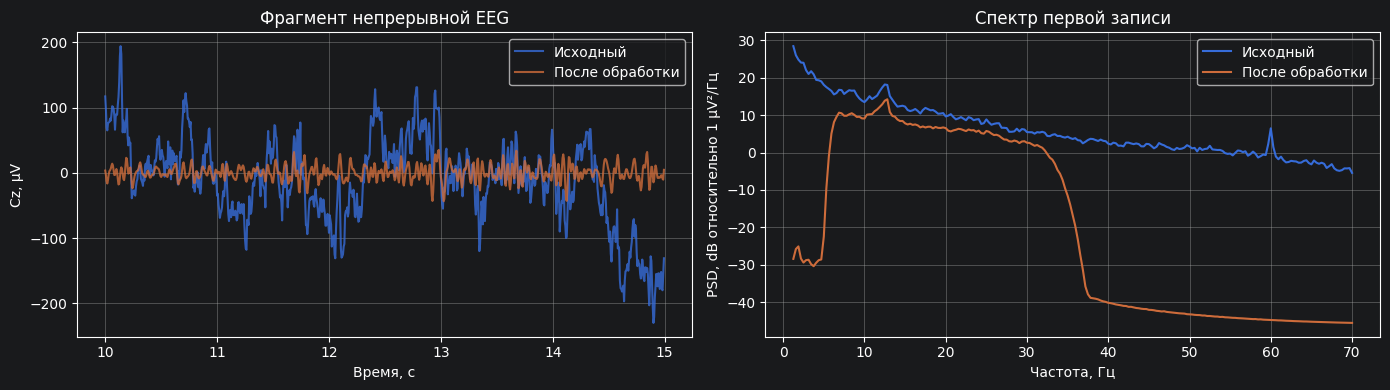

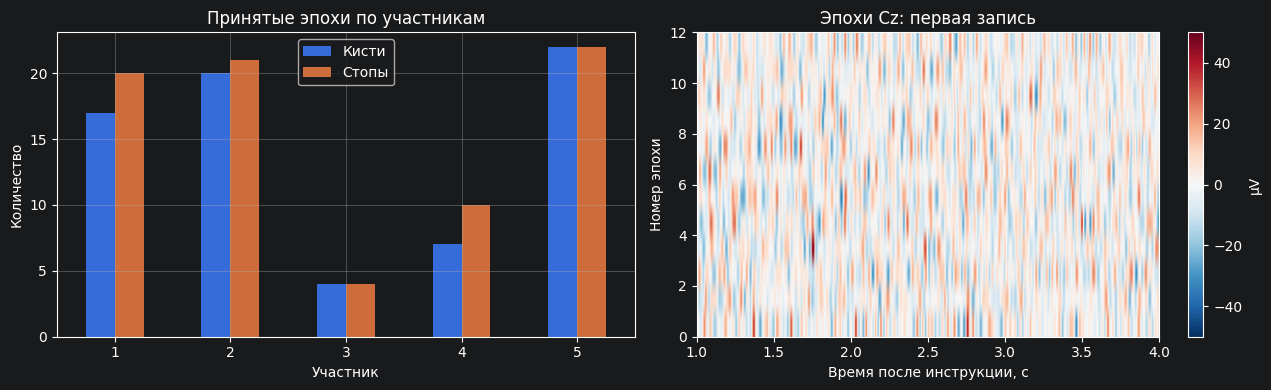

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for raw_obj, label in [(example_before, "Исходный"), (example_after, "После обработки")]:
    start, stop = int(10 * sfreq), int(15 * sfreq)
    signal = raw_obj.get_data(picks=["Cz"], start=start, stop=stop)[0] * 1e6
    axes[0].plot(np.arange(len(signal)) / sfreq + 10, signal, label=label, alpha=0.8)
    spec = raw_obj.compute_psd(method="welch", fmin=1, fmax=70,
                               n_fft=512, verbose="ERROR")
    power, freq = spec.get_data(return_freqs=True)
    axes[1].plot(freq, 10 * np.log10(np.maximum(power.mean(axis=0) * 1e12, 1e-20)), label=label)
axes[0].set(xlabel="Время, с", ylabel="Cz, μV", title="Фрагмент непрерывной EEG")
axes[1].set(xlabel="Частота, Гц", ylabel="PSD, dB относительно 1 μV²/Гц", title="Спектр первой записи")
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "01_preprocessing.png", dpi=140)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
counts = pd.crosstab(metadata.subject, metadata.y).reindex(columns=[0, 1], fill_value=0)
counts.columns = CLASS_NAMES
counts.plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Принятые эпохи по участникам", xlabel="Участник", ylabel="Количество")
cz = example_epochs.get_data(picks=["Cz"])[:, 0, :] * 1e6
im = axes[1].imshow(cz, aspect="auto", origin="lower", cmap="RdBu_r",
                     extent=[TMIN, TMAX, 0, len(cz)], vmin=-50, vmax=50)
axes[1].set(title="Эпохи Cz: первая запись", xlabel="Время после инструкции, с", ylabel="Номер эпохи")
axes[1].grid(False)
fig.colorbar(im, ax=axes[1], label="μV")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "02_epochs.png", dpi=140)
plt.show()


## 5. Выделение признаков через MNE

Для каждой эпохи и каждого выбранного канала вычисляем PSD методом Welch:
окно 2 с, перекрытие 1 с. Интегрируем PSD по μ (8 ≤ f < 13 Гц) и β
(13 ≤ f ≤ 30 Гц). Получаем 15 × 2 = **30 признаков на эпоху**.

Признак: $x_{c,b}=\log_{10}(\max(\sum_{f\in b} PSD_c(f)\Delta f,10^{-30}))$.
PSD имеет единицы V²/Гц, мощность — V²; логарифм берётся от численного значения
в этих единицах. Логарифм уменьшает асимметрию распределения мощности.
Сенсомоторные ритмы выбраны по смыслу задачи, без отбора на внешних фолдах.

Функция работает с каждой эпохой независимо и ничего не обучает: её допустимо
вызвать до разбиения. **StandardScaler обучается только внутри Pipeline на train.**


In [7]:
def extract_features(epoch_data, sample_rate):
    n_fft = int(round(2 * sample_rate))
    if epoch_data.shape[-1] < n_fft:
        raise ValueError("Эпоха должна содержать хотя бы 2 секунды EEG")
    psd, freqs = mne.time_frequency.psd_array_welch(
        epoch_data, sfreq=sample_rate, fmin=8, fmax=30,
        n_fft=n_fft, n_per_seg=n_fft, n_overlap=n_fft // 2,
        average="mean", window="hamming", verbose="ERROR",
    )
    df = freqs[1] - freqs[0]
    blocks, names = [], []
    for band, (low, high) in BANDS.items():
        upper = freqs <= high if band == "beta" else freqs < high
        mask = (freqs >= low) & upper
        power = psd[..., mask].sum(axis=-1) * df
        blocks.append(np.log10(np.maximum(power, 1e-30)))
        names.extend([f"{ch}_{band}_logpower" for ch in CHANNELS])
    return np.concatenate(blocks, axis=1), names

X, feature_names = extract_features(E, sfreq)
assert X.shape == (len(y), len(CHANNELS) * len(BANDS))
assert np.isfinite(X).all()
display(pd.DataFrame(X, columns=feature_names).head())
print("X:", X.shape, "; y:", y.shape, "; классы:", np.bincount(y))


,FC3_mu_logpower,FC1_mu_logpower,FCz_mu_logpower,FC2_mu_logpower,FC4_mu_logpower,C3_mu_logpower,C1_mu_logpower,Cz_mu_logpower,C2_mu_logpower,C4_mu_logpower,...,C3_beta_logpower,C1_beta_logpower,Cz_beta_logpower,C2_beta_logpower,C4_beta_logpower,CP3_beta_logpower,CP1_beta_logpower,CPz_beta_logpower,CP2_beta_logpower,CP4_beta_logpower
0,-9.925187,-10.077816,-10.318395,-10.221783,-10.161658,-10.010245,-10.280925,-10.523573,-10.334233,-10.231219,...,-10.299435,-10.369338,-10.207650,-10.332771,-10.461021,-10.439600,-10.438392,-10.319570,-10.561084,-10.579297
1,-10.801542,-10.685065,-10.517053,-10.664376,-10.774268,-10.957200,-10.719542,-10.465504,-10.730003,-10.803340,...,-10.579034,-10.682491,-10.542777,-10.549893,-10.636848,-10.645866,-10.727858,-10.817420,-10.850707,-10.745617
2,-10.149584,-10.170396,-10.105198,-10.140467,-10.176866,-10.232582,-10.486648,-10.486764,-10.368124,-10.355149,...,-10.178606,-10.273884,-10.202807,-10.356210,-10.363565,-10.452784,-10.501235,-10.409609,-10.472873,-10.455890
3,-10.591642,-10.542461,-10.547727,-10.587495,-10.626633,-10.561518,-10.512577,-10.468083,-10.508709,-10.521669,...,-10.271262,-10.352438,-10.399813,-10.357163,-10.267951,-10.442942,-10.506942,-10.563856,-10.536927,-10.364996
4,-10.265337,-10.356321,-10.369335,-10.412715,-10.247294,-10.320467,-10.475573,-10.481501,-10.317947,-10.360652,...,-10.282526,-10.352068,-10.231317,-10.241427,-10.281006,-10.358214,-10.495076,-10.467001,-10.499618,-10.351109


X: (147, 30) ; y: (147,) ; классы: [70 77]


## 6. Модель и честная схема кросс-валидации

Logistic Regression оценивает $P(y=1\mid x)=\sigma(w^T x+b)$.
Регуляризация L2 ограничивает величину весов; чем меньше `C`, тем она сильнее.
Перебираются 7 заранее заданных значений C от 0.001 до 1000.
`class_weight='balanced'` учитывает дисбаланс классов в обучающей части.

**Внешний Leave-One-Subject-Out (5 фолдов):** четыре участника для обучения,
пятый — только для оценки. Каждый человек один раз побывает во внешнем test.
**Внутренний Leave-One-Subject-Out (4 фолда):** на этих четырёх участниках
`GridSearchCV` выбирает C по balanced accuracy. Scaler переобучается в каждом
внутреннем фолде; после выбора C весь Pipeline переобучается на внешнем train.

`LogisticRegression + GridSearchCV` реализует требуемую Logistic Regression с CV.
Здесь специально не используется `Pipeline(StandardScaler, LogisticRegressionCV)`:
так scaler был бы обучен до внутренних разбиений LogisticRegressionCV.
Поиск по **всему Pipeline** исключает эту утечку.

Основная метрика — balanced accuracy (средний recall двух классов).
Дополнительно: accuracy, macro-F1 и ROC-AUC. DummyClassifier всегда выбирает
наиболее частый класс train и служит baseline. Оценка касается уже принятых
эпох: на отклонённых эпохах модель не проверяется.


In [8]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(solver="lbfgs", max_iter=5000,
                              class_weight="balanced", random_state=SEED)),
])
outer_cv = LeaveOneGroupOut()
oof_pred = np.full(len(y), -1, dtype=int)
oof_proba = np.full(len(y), np.nan)
dummy_pred = np.full(len(y), -1, dtype=int)
seen = np.zeros(len(y), dtype=int)
fold_rows, search_rows = [], []

for fold, (train, test) in enumerate(outer_cv.split(X, y, groups), start=1):
    assert set(groups[train]).isdisjoint(set(groups[test]))
    inner_splits = list(LeaveOneGroupOut().split(X[train], y[train], groups[train]))
    for inner_train, inner_valid in inner_splits:
        assert set(groups[train][inner_train]).isdisjoint(set(groups[train][inner_valid]))
        assert set(y[train][inner_train]) == set(y[train][inner_valid]) == {0, 1}
    search = GridSearchCV(
        clone(pipeline), {"lr__C": C_GRID}, cv=inner_splits,
        scoring="balanced_accuracy", refit=True, n_jobs=1, error_score="raise",
    )
    search.fit(X[train], y[train])
    pred = search.predict(X[test])
    proba = search.predict_proba(X[test])[:, 1]
    baseline = DummyClassifier(strategy="most_frequent").fit(X[train], y[train])
    dpred = baseline.predict(X[test])
    oof_pred[test], oof_proba[test], dummy_pred[test] = pred, proba, dpred
    seen[test] += 1
    held_out = int(groups[test][0])
    fold_rows.append({
        "test_subject": held_out, "n_train": len(train), "n_test": len(test),
        "best_C": float(search.best_params_["lr__C"]),
        "inner_best_balanced_accuracy": float(search.best_score_),
        "balanced_accuracy": balanced_accuracy_score(y[test], pred),
        "accuracy": accuracy_score(y[test], pred),
        "f1_macro": f1_score(y[test], pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y[test], proba),
        "dummy_balanced_accuracy": balanced_accuracy_score(y[test], dpred),
    })
    table = pd.DataFrame(search.cv_results_)
    table["test_subject"] = held_out
    search_rows.append(table[["test_subject", "param_lr__C", "mean_test_score", "std_test_score", "rank_test_score"]])
    print(f"Фолд {fold}: test=S{held_out:03d}, C={search.best_params_['lr__C']:g}, "
          f"balanced accuracy={fold_rows[-1]['balanced_accuracy']:.3f}")

fold_results = pd.DataFrame(fold_rows)
assert (seen == 1).all() and (oof_pred >= 0).all() and np.isfinite(oof_proba).all()
display(fold_results)
metrics = ["balanced_accuracy", "accuracy", "f1_macro", "roc_auc", "dummy_balanced_accuracy"]
summary = fold_results[metrics].agg(["mean", "std"]).T
summary.columns = ["mean_across_subjects", "std_across_subjects"]
display(summary)


Фолд 1: test=S001, C=1, balanced accuracy=0.507
Фолд 2: test=S002, C=100, balanced accuracy=0.548
Фолд 3: test=S003, C=1000, balanced accuracy=0.250
Фолд 4: test=S004, C=1000, balanced accuracy=0.429
Фолд 5: test=S005, C=0.001, balanced accuracy=0.523


,test_subject,n_train,n_test,best_C,inner_best_balanced_accuracy,balanced_accuracy,accuracy,f1_macro,roc_auc,dummy_balanced_accuracy
0,1,110,37,1.000,0.493534,0.507353,0.486486,0.461303,0.450000,0.5
1,2,106,41,100.000,0.562667,0.547619,0.536585,0.425940,0.683333,0.5
2,3,139,8,1000.000,0.556005,0.250000,0.250000,0.200000,0.375000,0.5
3,4,130,17,1000.000,0.518191,0.428571,0.352941,0.260870,0.500000,0.5
4,5,103,44,0.001,0.510417,0.522727,0.522727,0.381940,0.446281,0.5


,mean_across_subjects,std_across_subjects
balanced_accuracy,0.451254,0.120995
accuracy,0.429748,0.123983
f1_macro,0.346010,0.111288
roc_auc,0.490923,0.116415
dummy_balanced_accuracy,0.500000,0.000000


## 7. Ошибки и итоговые показатели

Главный результат — средняя balanced accuracy по внешним участникам.
Стандартное отклонение показывает разброс между ними, **не доверительный интервал**.
Матрица ошибок и classification report объединяют out-of-fold предсказания:
каждая эпоха предсказана моделью, которая не видела её участника при обучении.
Объединённые метрики взвешивают участников числом эпох; средние по фолдам дают
всем участникам одинаковый вес. На ROC показаны отдельные внешние фолды, поскольку
вероятности разных обученных моделей могут иметь разные масштабы.


              precision    recall  f1-score   support

       Кисти       0.48      0.87      0.62        70
       Стопы       0.53      0.13      0.21        77

    accuracy                           0.48       147
   macro avg       0.50      0.50      0.41       147
weighted avg       0.50      0.48      0.40       147



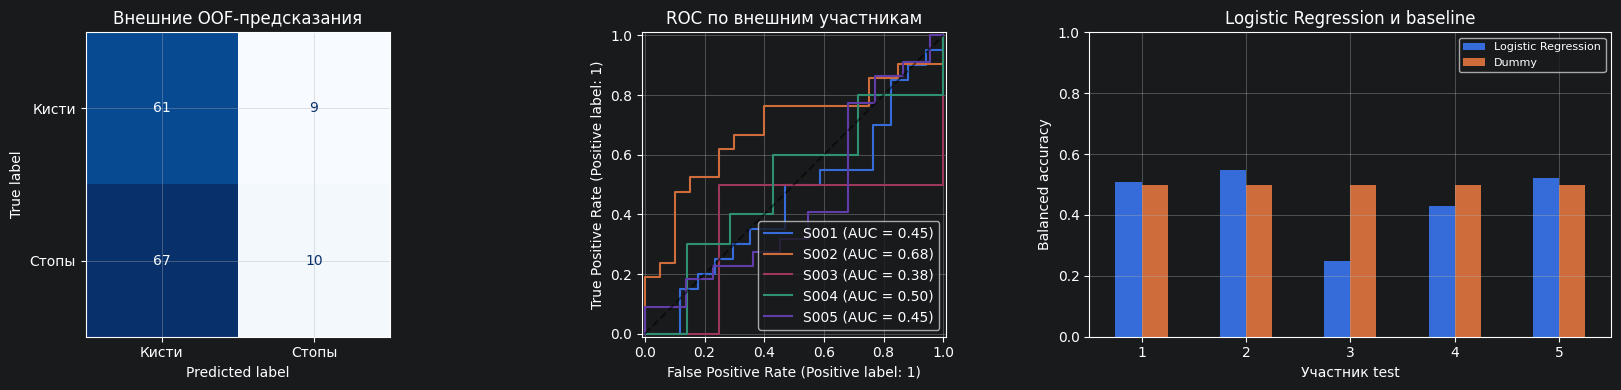

**Результат:** 147 эпох, 30 признаков; внешняя balanced accuracy = **0.451 ± 0.121** (среднее ± SD по 5 участникам). Baseline = **0.500**. Среднее качество не выше baseline. Это описательное сравнение, а не доказательство статистической значимости.

In [9]:
print(classification_report(y, oof_pred, labels=[0, 1], target_names=CLASS_NAMES, zero_division=0))
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
ConfusionMatrixDisplay.from_predictions(y, oof_pred, labels=[0, 1],
    display_labels=CLASS_NAMES, cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Внешние OOF-предсказания")
for subject in SUBJECTS:
    mask = groups == subject
    RocCurveDisplay.from_predictions(y[mask], oof_proba[mask],
                                    name=f"S{subject:03d}", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[1].set_title("ROC по внешним участникам")
fold_results.set_index("test_subject")[["balanced_accuracy", "dummy_balanced_accuracy"]].plot.bar(ax=axes[2], rot=0)
axes[2].set(ylim=(0, 1), title="Logistic Regression и baseline", ylabel="Balanced accuracy", xlabel="Участник test")
axes[2].legend(["Logistic Regression", "Dummy"], fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "03_evaluation.png", dpi=140)
plt.show()

mean_ba = float(fold_results.balanced_accuracy.mean())
std_ba = float(fold_results.balanced_accuracy.std())
dummy_ba = float(fold_results.dummy_balanced_accuracy.mean())
comparison = ("выше" if mean_ba > dummy_ba else "не выше")
display(Markdown(
    f"**Результат:** {len(y)} эпох, {X.shape[1]} признаков; "
    f"внешняя balanced accuracy = **{mean_ba:.3f} ± {std_ba:.3f}** "
    f"(среднее ± SD по {len(SUBJECTS)} участникам). "
    f"Baseline = **{dummy_ba:.3f}**. Среднее качество {comparison} baseline. "
    "Это описательное сравнение, а не доказательство статистической значимости."
))


## 8. Финальная модель и сохранение результатов

После завершения оценки отдельно подбираем C по CV на всех доступных участниках
и обучаем финальный Pipeline на всех принятых эпохах. Эта модель предназначена
для последующего применения; её качество здесь **не оценивается на train**.
Честная оценка процедуры уже получена внешними фолдами выше.

Файл модели содержит scaler + classifier и описание обработки. Он принимает
готовые признаки в том же порядке, а не произвольный EDF. Для нового EEG нужно
повторить ту же референцию, фильтрацию, эпохирование, порядок каналов и Welch.
Положительные коэффициенты связаны с классом «Стопы», отрицательные — «Кисти»;
это ассоциации стандартизованных признаков, не доказательство причинности.


In [10]:
final_splits = list(LeaveOneGroupOut().split(X, y, groups))
final_search = GridSearchCV(
    clone(pipeline), {"lr__C": C_GRID}, cv=final_splits,
    scoring="balanced_accuracy", refit=True, n_jobs=1, error_score="raise",
).fit(X, y)
final_model = final_search.best_estimator_
print("C финальной модели:", final_search.best_params_["lr__C"])

coefficients = pd.Series(final_model.named_steps["lr"].coef_[0], index=feature_names)
display(coefficients.rename("standardized_coefficient").to_frame().sort_values(
    "standardized_coefficient", key=lambda s: s.abs(), ascending=False).head(10))

config = {
    "data_source": DATA_SOURCE,
    "subjects": SUBJECTS, "runs": RUNS, "channels": CHANNELS,
    "event_id": EVENT_ID, "classes": CLASS_NAMES, "sfreq": sfreq,
    "tmin": TMIN, "tmax": TMAX, "bandpass": FILTER,
    "reference": "average over all EEG channels before channel selection",
    "reject_uv": REJECT_UV, "flat_uv": 0.1, "bands": BANDS,
    "welch_window_seconds": 2, "welch_overlap_seconds": 1,
    "feature_names": feature_names, "C_grid": C_GRID.tolist(),
    "seed": SEED, "evaluation": "nested leave-one-subject-out",
}
joblib.dump({"pipeline": final_model, "config": config, "versions": VERSIONS},
            RESULTS_DIR / "eeg_logreg.joblib")
fold_results.to_csv(RESULTS_DIR / "cv_folds.csv", index=False)
summary.to_csv(RESULTS_DIR / "cv_summary.csv")
pd.concat(search_rows, ignore_index=True).to_csv(RESULTS_DIR / "inner_cv_search.csv", index=False)
qc.to_csv(RESULTS_DIR / "quality_control.csv", index=False)
predictions = metadata.copy()
predictions["prediction"] = oof_pred
predictions["p_feet"] = oof_proba
predictions["dummy_prediction"] = dummy_pred
predictions.to_csv(RESULTS_DIR / "oof_predictions.csv", index=False)
pd.concat([metadata, pd.DataFrame(X, columns=feature_names)], axis=1).to_csv(
    RESULTS_DIR / "features.csv", index=False)
coefficients.rename("coefficient").to_csv(RESULTS_DIR / "coefficients.csv")
with (RESULTS_DIR / "experiment.json").open("w", encoding="utf-8") as file:
    json.dump({"config": config, "versions": VERSIONS, "data_manifest": manifest,
               "mean_balanced_accuracy": mean_ba, "std_balanced_accuracy": std_ba,
               "baseline_balanced_accuracy": dummy_ba,
               "final_C": float(final_search.best_params_["lr__C"])},
              file, ensure_ascii=False, indent=2)
print("Сохранено в:", RESULTS_DIR.resolve())


C финальной модели: 0.001


,standardized_coefficient
C3_mu_logpower,0.010861
CPz_mu_logpower,-0.007549
FC4_mu_logpower,0.006984
C4_mu_logpower,0.006597
C1_mu_logpower,0.006318
CP2_mu_logpower,-0.005957
FC3_mu_logpower,0.005521
CP3_beta_logpower,0.005345
Cz_beta_logpower,-0.004926
FC2_mu_logpower,0.004712


Сохранено в: C:\Users\deste\Documents\ChatGPT\ucheba1\results


## 9. Выводы, ограничения и ответы для защиты

Пайплайн прошёл путь от непрерывного EEG до предсказаний: загрузка → стандартизация
каналов → монтаж → средняя референция → FIR-фильтр → события → эпохи → контроль
артефактов → логарифмы спектральной мощности → масштабирование → Logistic Regression.
Численный вывод для текущего запуска автоматически сформирован в разделе 7.

**Почему не случайный train/test split эпох?** Эпохи одного человека имеют общие
особенности записи. Их попадание в обе части может завысить оценку переноса на
нового человека. Здесь группы не пересекаются ни во внешней, ни во внутренней CV.

**Зачем две CV?** Внутренняя выбирает C, внешняя оценивает всю процедуру выбора.
`best_score_` внутреннего поиска нельзя выдавать за независимую итоговую точность.

**Что означает C?** Обратная сила регуляризации: малое C сильнее ограничивает веса.
**Зачем scaler?** Он приводит признаки к сопоставимым масштабам, чтобы L2-регуляризация
не зависела от их разброса. Scaler обучается только на соответствующей train-части.

**Ограничения:** пять участников — небольшая подвыборка; качество может сильно
различаться между людьми. Амплитудная отбраковка не устраняет все артефакты,
а исключённые эпохи могут быть труднее оставшихся. Офлайн-фильтр использует
будущие отсчёты, поэтому результат не подтверждает работу в реальном времени.
Общая референция может распространять влияние плохого канала; автоматическое
выявление плохих каналов и ICA требуют отдельной проверки. Отдельной внешней
когорты и проверки статистической значимости здесь нет. На большем наборе людей
оценка будет надёжнее. CSP и другие признаки можно исследовать как будущие варианты,
обучая любые подбираемые преобразования внутри CV.